In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)



In [2]:
# 1. Load dataset
df = pd.read_excel('Berlin_wind_multiclass1.xlsx')

In [3]:


target = "X50Hertz..MW."

print("Dataset shape:", df.shape)



Dataset shape: (70080, 24)


In [4]:
# 2. Randomly split the dataset into 80:20
# First split the continuous target to avoid sorting bias
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

train_df = train_df.copy()
test_df = test_df.copy()

# 3. Calculate class boundaries using training data only
thresholds = train_df[target].quantile(
    [0.2, 0.4, 0.6, 0.8]
).to_numpy()

thresholds = np.unique(thresholds)

print("Class thresholds (MW):", thresholds)



Class thresholds (MW): [ 34.04   71.21  125.82  234.296]


In [5]:
# 4. Convert continuous target into five classes
y_train = np.digitize(
    train_df[target].to_numpy(),
    thresholds
)

y_test = np.digitize(
    test_df[target].to_numpy(),
    thresholds
)

print("\nTraining classes:",
      np.unique(y_train, return_counts=True))

print("Testing classes:",
      np.unique(y_test, return_counts=True))




Training classes: (array([0, 1, 2, 3, 4]), array([11183, 11234, 11218, 11216, 11213]))
Testing classes: (array([0, 1, 2, 3, 4]), array([2717, 2856, 2718, 2920, 2805]))


In [6]:
# 5. Drop target and time-related columns
drop_cols = [
    target,
    "Year", "Month", "Day", "Hour", "Minute"
]

X_train = train_df.drop(
    columns=drop_cols,
    errors="ignore"
)

X_test = test_df.drop(
    columns=drop_cols,
    errors="ignore"
)

print("\nNumber of features:", X_train.shape[1])




Number of features: 18


In [11]:
# 6. Train XGBoost model
model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(np.unique(y_train)),
    n_estimators=500,
    max_depth=5,
    learning_rate=0.5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)



In [12]:
model.fit(X_train, y_train)

print("\nTraining completed!")




Training completed!


In [13]:
# 7. Predictions
pred = model.predict(X_test)

# 8. Evaluation
print("\nAccuracy:",
      accuracy_score(y_test, pred))

print("Macro-F1:",
      f1_score(y_test, pred, average="macro"))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        pred,
        zero_division=0
    )
)




Accuracy: 0.933861301369863
Macro-F1: 0.9339150712354177

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      2717
           1       0.90      0.91      0.91      2856
           2       0.90      0.91      0.90      2718
           3       0.94      0.93      0.93      2920
           4       0.97      0.98      0.97      2805

    accuracy                           0.93     14016
   macro avg       0.93      0.93      0.93     14016
weighted avg       0.93      0.93      0.93     14016



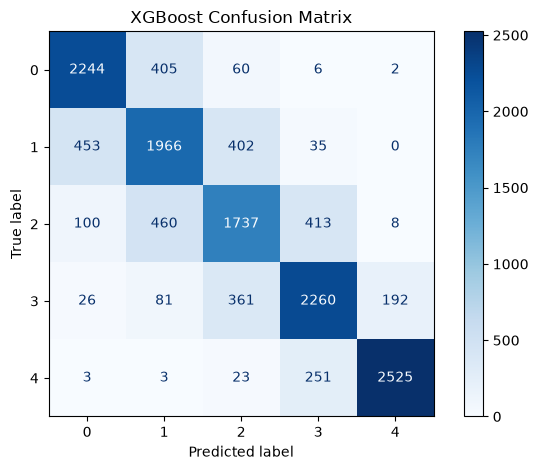


Training class proportions:
0    0.199468
1    0.200378
2    0.200093
3    0.200057
4    0.200004
Name: proportion, dtype: float64

Testing class proportions:
0    0.193850
1    0.203767
2    0.193921
3    0.208333
4    0.200128
Name: proportion, dtype: float64


In [10]:
# 9. Confusion Matrix
labels = np.arange(len(thresholds) + 1)

cm = confusion_matrix(
    y_test,
    pred,
    labels=labels
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues")

plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

# 10. Compare class distributions
print("\nTraining class proportions:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())

print("\nTesting class proportions:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())
